In [1]:
from pathlib import Path

import torch
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap, BoundaryNorm

from floodvision.datasets.flood_dataset import FloodDataset

from floodvision.preprocessing.transforms import (
    get_train_transforms,
    get_val_transforms
)

BASE_DIR = Path.cwd().resolve()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent
elif (BASE_DIR / "ml" / "configs").is_dir():
    BASE_DIR = BASE_DIR / "ml"

DATASET_CONFIG = BASE_DIR / "configs/dataset.yaml"

PREPROCESSING_CONFIG = (
    BASE_DIR / "configs/preprocessing.yaml"
)

SPLIT_DIR = BASE_DIR / "data/splits/geographical"

In [2]:
train_dataset = FloodDataset(
    dataset_config_path=DATASET_CONFIG,
    preprocessing_config_path=PREPROCESSING_CONFIG,
    split_path=SPLIT_DIR / "train.csv",
    transforms=get_train_transforms()
)

val_dataset = FloodDataset(
    dataset_config_path=DATASET_CONFIG,
    preprocessing_config_path=PREPROCESSING_CONFIG,
    split_path=SPLIT_DIR / "val.csv",
    transforms=get_val_transforms()
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

Training samples: 340
Validation samples: 48


In [3]:
sample = train_dataset[0]

image = sample["image"]
mask = sample["mask"]

print("Sample ID:", sample["sample_id"])

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)

print("Image dtype:", image.dtype)
print("Mask dtype:", mask.dtype)

print("Mask labels:", torch.unique(mask))

print("Image is finite:", torch.isfinite(image).all().item())

assert image.shape == (2, 512, 512)
assert mask.shape == (1, 512, 512)

assert torch.isfinite(image).all()

assert torch.isin(
    mask,
    torch.tensor([-1.0, 0.0, 1.0])
).all()

Sample ID: Bolivia_103757
Image shape: torch.Size([2, 512, 512])
Mask shape: torch.Size([1, 512, 512])
Image dtype: torch.float32
Mask dtype: torch.float32
Mask labels: tensor([-1.,  0.,  1.])
Image is finite: True


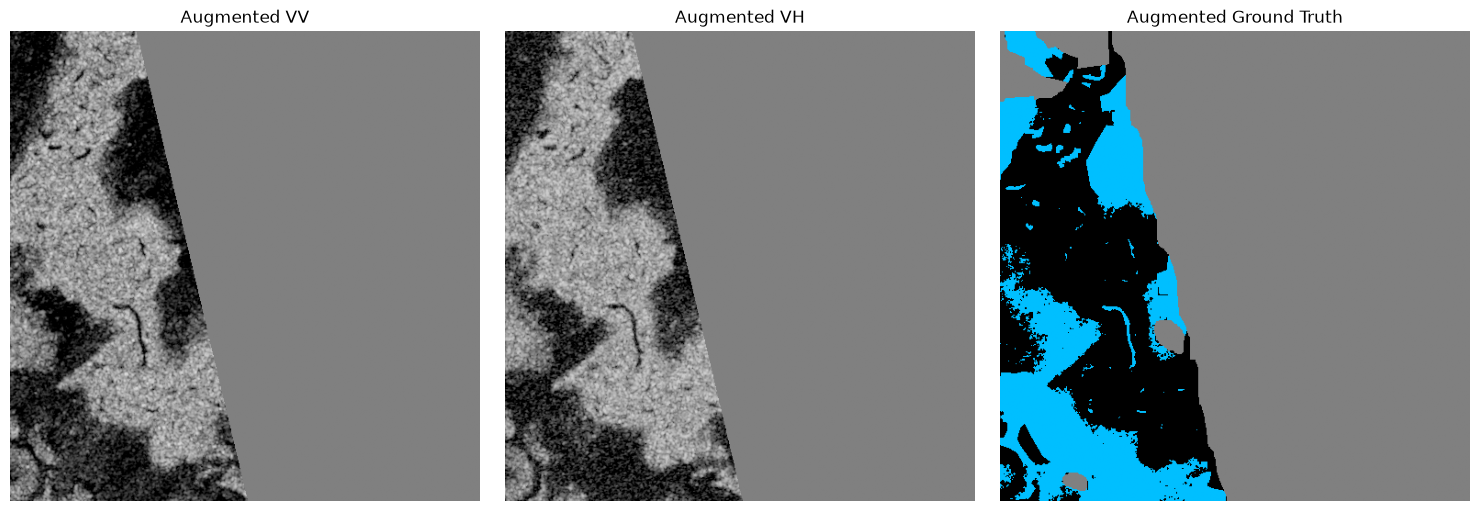

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(
    image[0].numpy(),
    cmap="gray",
    vmin=-3,
    vmax=3
)

axes[0].set_title("Augmented VV")

axes[1].imshow(
    image[1].numpy(),
    cmap="gray",
    vmin=-3,
    vmax=3
)

axes[1].set_title("Augmented VH")

cmap = ListedColormap([
    "gray",
    "black",
    "deepskyblue"
])

norm = BoundaryNorm(
    [-1.5, -0.5, 0.5, 1.5],
    cmap.N
)

axes[2].imshow(
    mask[0].numpy(),
    cmap=cmap,
    norm=norm
)

axes[2].set_title("Augmented Ground Truth")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [5]:
from torch.utils.data import DataLoader

generator = torch.Generator().manual_seed(42)

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0,
    pin_memory=False,
    generator=generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 85
Validation batches: 12


In [6]:
from tqdm.auto import tqdm

water_pixels = 0
non_water_pixels = 0
invalid_pixels = 0

for sample in tqdm(train_dataset):

    mask = sample["mask"]

    water_pixels += (mask == 1).sum().item()

    non_water_pixels += (mask == 0).sum().item()

    invalid_pixels += (mask == -1).sum().item()

if water_pixels == 0:
    raise ValueError("No water pixels in training data")

pos_weight = non_water_pixels / water_pixels

print("Water pixels:", water_pixels)
print("Non-water pixels:", non_water_pixels)
print("Invalid pixels:", invalid_pixels)

print("Positive class weight:", pos_weight)

  0%|          | 0/340 [00:00<?, ?it/s]

Water pixels: 6557923
Non-water pixels: 70009779
Invalid pixels: 12561258
Positive class weight: 10.67560247352706
